In [28]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:.2f}".format)

RAW_FILE = "cardio_train.csv"
CLEAN_FILE = "cardio_cleaned.csv"

# Plausibility limits used throughout the notebook
HEIGHT_LIMITS = (100, 220)    # cm
MIN_WEIGHT = 30               # kg
SYS_LIMITS = (70, 250)        # mmHg (ap_hi)
DIA_LIMITS = (40, 150)        # mmHg (ap_lo)

In [29]:
%pip install matplotlib seaborn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


## 1. Load & overview

In [30]:
raw = pd.read_csv(RAW_FILE, sep=";")

print("Dataset shape:", raw.shape)
print("Columns:", list(raw.columns))
print(f"Memory: {raw.memory_usage(deep=True).sum() / 1024:.1f} KB\n")

display(raw.head())
display(raw.dtypes.rename("dtype").to_frame())
raw.info()
display(raw.describe().T)

Dataset shape: (70000, 13)
Columns: ['id', 'age', 'gender', 'height', 'weight', 'ap_hi', 'ap_lo', 'cholesterol', 'gluc', 'smoke', 'alco', 'active', 'cardio']
Memory: 7109.5 KB



,id,age,gender,height,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,cardio
0,0,18393,2,168,62.00,110,80,1,1,0,0,1,0
1,1,20228,1,156,85.00,140,90,3,1,0,0,1,1
2,2,18857,1,165,64.00,130,70,3,1,0,0,0,1
3,3,17623,2,169,82.00,150,100,1,1,0,0,1,1
4,4,17474,1,156,56.00,100,60,1,1,0,0,0,0


,dtype
id,int64
age,int64
gender,int64
height,int64
weight,float64
ap_hi,int64
ap_lo,int64
cholesterol,int64
gluc,int64
smoke,int64


<class 'pandas.DataFrame'>
RangeIndex: 70000 entries, 0 to 69999
Data columns (total 13 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   id           70000 non-null  int64  
 1   age          70000 non-null  int64  
 2   gender       70000 non-null  int64  
 3   height       70000 non-null  int64  
 4   weight       70000 non-null  float64
 5   ap_hi        70000 non-null  int64  
 6   ap_lo        70000 non-null  int64  
 7   cholesterol  70000 non-null  int64  
 8   gluc         70000 non-null  int64  
 9   smoke        70000 non-null  int64  
 10  alco         70000 non-null  int64  
 11  active       70000 non-null  int64  
 12  cardio       70000 non-null  int64  
dtypes: float64(1), int64(12)
memory usage: 6.9 MB


,count,mean,std,min,25%,50%,75%,max
id,70000.00,49972.42,28851.30,0.00,25006.75,50001.50,74889.25,99999.00
age,70000.00,19468.87,2467.25,10798.00,17664.00,19703.00,21327.00,23713.00
gender,70000.00,1.35,0.48,1.00,1.00,1.00,2.00,2.00
height,70000.00,164.36,8.21,55.00,159.00,165.00,170.00,250.00
weight,70000.00,74.21,14.40,10.00,65.00,72.00,82.00,200.00
ap_hi,70000.00,128.82,154.01,-150.00,120.00,120.00,140.00,16020.00
ap_lo,70000.00,96.63,188.47,-70.00,80.00,80.00,90.00,11000.00
cholesterol,70000.00,1.37,0.68,1.00,1.00,1.00,2.00,3.00
gluc,70000.00,1.23,0.57,1.00,1.00,1.00,1.00,3.00
smoke,70000.00,0.09,0.28,0.00,0.00,0.00,0.00,1.00


In [31]:
COLS = {
    "identifier":  ["id"],
    "numerical":   ["age", "height", "weight", "ap_hi", "ap_lo"],
    "binary":      ["smoke", "alco", "active", "cardio"],
    "categorical": ["gender", "cholesterol", "gluc"],
}
NUM_COLS = COLS["numerical"]

## 2. Integrity checks

In [32]:
print("Missing values per column:")
print(raw.isna().sum().sum(), "total")
print("Fully duplicated rows:", raw.duplicated().sum())
print("Duplicated ids:", raw["id"].duplicated().sum())

Missing values per column:
0 total
Fully duplicated rows: 0
Duplicated ids: 0


In [33]:
for col in COLS["binary"]:
    print(raw[col].value_counts(dropna=False).sort_index(), end="\n\n")

smoke
0    63831
1     6169
Name: count, dtype: int64

alco
0    66236
1     3764
Name: count, dtype: int64

active
0    13739
1    56261
Name: count, dtype: int64

cardio
0    35021
1    34979
Name: count, dtype: int64



In [34]:
allowed = {
    "gender": {1, 2},
    "cholesterol": {1, 2, 3},
    "gluc": {1, 2, 3},
    "smoke": {0, 1},
    "alco": {0, 1},
    "active": {0, 1},
    "cardio": {0, 1},
}

for col, ok_values in allowed.items():
    n_bad = (~raw[col].isin(ok_values)).sum()
    print(f"{col:<12} -> {n_bad} invalid values")

print("\nAge (days): min =", raw["age"].min(),
      "| max =", raw["age"].max(),
      "| negatives =", (raw["age"] < 0).sum())

gender       -> 0 invalid values
cholesterol  -> 0 invalid values
gluc         -> 0 invalid values
smoke        -> 0 invalid values
alco         -> 0 invalid values
active       -> 0 invalid values
cardio       -> 0 invalid values

Age (days): min = 10798 | max = 23713 | negatives = 0


## 3. Anomaly audit

In [35]:
rules = {
    "Height outside 100-220 cm":    (raw["height"] < HEIGHT_LIMITS[0]) | (raw["height"] > HEIGHT_LIMITS[1]),
    "Weight below 30 kg":           raw["weight"] < MIN_WEIGHT,
    "Systolic BP <= 0":             raw["ap_hi"] <= 0,
    "Systolic BP > 300":            raw["ap_hi"] > 300,
    "Diastolic BP <= 0":            raw["ap_lo"] <= 0,
    "Diastolic BP > 200":           raw["ap_lo"] > 200,
    "Systolic BP <= Diastolic BP":  raw["ap_hi"] <= raw["ap_lo"],
    "Systolic BP below 60":         raw["ap_hi"] < 60,
}

audit = pd.Series({name: int(mask.sum()) for name, mask in rules.items()},
                  name="rows_flagged")
display(audit.to_frame())

,rows_flagged
Height outside 100-220 cm,30
Weight below 30 kg,7
Systolic BP <= 0,7
Systolic BP > 300,40
Diastolic BP <= 0,22
Diastolic BP > 200,953
Systolic BP <= Diastolic BP,1236
Systolic BP below 60,188


### 3.1 Height

In [36]:
bad_height = rules["Height outside 100-220 cm"]
display(raw.loc[bad_height, "height"].value_counts().sort_index())

detail_cols = ["id", "age", "gender", "height", "weight", "ap_hi", "ap_lo", "cardio"]
print(raw.loc[bad_height, detail_cols].to_string())

height
55     1
57     1
59     1
60     1
64     1
65     2
66     1
67     3
68     2
70     3
71     1
72     1
74     1
75     2
76     1
80     1
81     1
91     1
96     1
97     1
98     1
99     1
250    1
Name: count, dtype: int64

          id    age  gender  height  weight  ap_hi  ap_lo  cardio
224      309  21800       2      76   55.00    120     80       0
6486    9223  21220       1     250   86.00    140    100       1
7598   10843  14661       2      70   72.00    120      8       0
8171   11662  17646       2      97  170.00    160    100       1
12770  18218  19594       1      75  168.00    120     80       1
13265  18928  22456       2      71   68.00    120     80       0
14323  20459  22005       1      67   57.00    120     90       1
15167  21686  15812       1      70   68.00    120     80       0
16699  23859  19680       2      74   98.00    140     90       1
17277  24690  17530       1      98   45.00     12     80       0
22542  32207  14538       1      68   65.00    100     60       0
22723  32456  23386       1      55   81.00    130     90       1
23913  34186  19074       1      81  156.00    140     90       0
27384  39156  15292       1      80  178.00    140     90       1
27603  394

- **250 cm** is almost certainly a recording error.
- **55-99 cm** is implausible for adults aged roughly 40-64.
- Some of these rows also carry unrealistic blood pressure values, handled in the BP section.

### 3.2 Weight

In [37]:
bad_weight = rules["Weight below 30 kg"]
display(raw.loc[bad_weight, "weight"].value_counts().sort_index())
print(raw.loc[bad_weight, detail_cols].to_string())

weight
10.00    1
11.00    1
21.00    1
22.00    1
23.00    1
28.00    1
29.00    1
Name: count, dtype: int64

          id    age  gender  height  weight  ap_hi  ap_lo  cardio
26806  38312  23284       1     157   23.00    110     80       0
29488  42156  20408       2     177   22.00    120     80       0
33817  48318  21582       2     178   11.00    130     90       1
34276  48976  14664       2     128   28.00    120     80       0
57858  82567  18804       2     165   10.00    180   1100       1
60188  85931  21855       1     162   21.00    120     80       1
60699  86650  18875       1     171   29.00    110     70       1


All seven cases need attention, especially the 10 kg and 11 kg weights for people taller than 160 cm. The data alone cannot prove every one of them is an error, but they are not plausible adult weights.

### 3.3 Blood pressure

In [38]:
# Systolic: non-positive and very high values
print("Systolic BP <= 0")
print(raw.loc[rules["Systolic BP <= 0"], "ap_hi"].value_counts().sort_index(), end="\n\n")
print(raw.loc[rules["Systolic BP <= 0"], detail_cols].to_string(), end="\n\n")

print("Systolic BP > 300")
print(raw.loc[rules["Systolic BP > 300"], "ap_hi"].value_counts().sort_index())

Systolic BP <= 0
ap_hi
-150    1
-140    1
-120    2
-115    1
-100    2
Name: count, dtype: int64

          id    age  gender  height  weight  ap_hi  ap_lo  cardio
4607    6525  15281       1     165   78.00   -100     80       0
16021  22881  22108       2     161   90.00   -115     70       0
20536  29313  15581       1     153   54.00   -100     70       0
23988  34295  18301       1     162   74.00   -140     90       1
25240  36025  14711       2     168   50.00   -120     80       1
35040  50055  23325       2     168   59.00   -150     80       1
46627  66571  23646       2     160   59.00   -120     80       0

Systolic BP > 300
ap_hi
309      1
401      1
701      1
806      1
902      1
906      6
907      3
909      1
960      1
1110     1
1130     1
1202     1
1205     1
1300     2
1400     3
1409     1
1420     2
1500     1
1620     1
2000     1
11020    1
11500    1
13010    2
14020    4
16020    1
Name: count, dtype: int64


In [39]:
# Diastolic: non-positive values
print("Diastolic BP <= 0")
print(raw.loc[rules["Diastolic BP <= 0"], "ap_lo"].value_counts().sort_index())
print(raw.loc[rules["Diastolic BP <= 0"], detail_cols].to_string(index=False))

Diastolic BP <= 0
ap_lo
-70     1
 0     21
Name: count, dtype: int64
   id   age  gender  height  weight  ap_hi  ap_lo  cardio
 2845 22712       2     167   59.00    906      0       0
19258 14965       2     150   60.00    130      0       0
23512 20457       1     156   50.00    138      0       1
24837 18226       1     164   78.00    138      0       0
32749 21182       2     166   68.00    149      0       1
34120 16131       1     161   92.00    906      0       1
36325 17952       2     176   73.00     12      0       0
39577 23396       2     180   73.00    140      0       1
45400 16070       1     170   64.00    907      0       0
54780 23208       2     170   81.00    148      0       0
57646 20322       1     162   50.00    309      0       0
59301 20970       1     154   41.00    806      0       0
60565 17988       2     176   69.00    906      0       0
62754 18802       1     164   78.00    108      0       0
65470 19597       2     165   70.00    140      0       0
68

In [40]:
# Diastolic: very high values
high_dia = raw.loc[rules["Diastolic BP > 200"], "ap_lo"]
print(high_dia.value_counts().sort_index().to_string())
print("\nMin:", high_dia.min(), "| Max:", high_dia.max())
print("\nMost frequent values:")
print(high_dia.value_counts().head(10))

ap_lo
585        1
602        1
700        1
708        2
709        2
710        2
800        5
801        2
802        1
809        3
810        1
820        1
850        2
870        1
880        1
900        2
901        1
902        2
910        1
1000     666
1001       8
1002       1
1003       2
1007       1
1008       4
1011       2
1022       1
1033       2
1044       1
1077       1
1088       2
1100     156
1101       1
1110      11
1111       1
1120       5
1125       1
1139       1
1140       1
1177       2
1200      21
1211       1
1400       2
1900       2
2088       1
5700       2
6800       1
7099       1
7100       1
8000       2
8044       1
8077       1
8079       1
8099       3
8100       1
8200       1
8500       1
9011       2
9100       1
9800       1
10000      3
11000      1

Min: 585 | Max: 11000

Most frequent values:
ap_lo
1000     666
1100     156
1200      21
1110      11
1001       8
800        5
1120       5
1008       4
10000      3
8099       3
Name: 

In [41]:
# Rows where systolic is not greater than diastolic
order_viol = raw.loc[rules["Systolic BP <= Diastolic BP"], ["ap_hi", "ap_lo"]]
print("Rows:", len(order_viol))
print(order_viol.value_counts().head(20))

Rows: 1236
ap_hi  ap_lo
150    1000     197
160    1000     169
140    1000     141
12     80        67
180    1000      47
160    1100      46
170    1000      42
150    1100      31
130    1000      28
180    1100      28
80     120       24
140    1100      19
190    1000      17
14     90        16
170    1100      15
11     70        14
90     140        9
120    1000       8
90     130        8
70     110        7
Name: count, dtype: int64


In [42]:
low_sys = raw.loc[rules["Systolic BP below 60"], "ap_hi"]
print(low_sys.value_counts().sort_index().to_string())
print("\nMin:", low_sys.min(), "| Max:", low_sys.max(), "| Rows:", len(low_sys))
print("Negative:", (low_sys < 0).sum(), "| Positive but below 60:", (low_sys > 0).sum())

ap_hi
-150     1
-140     1
-120     2
-115     1
-100     2
 1       2
 7       1
 10      7
 11     28
 12     76
 13     15
 14     29
 15     12
 16      3
 17      3
 20      4
 24      1

Min: -150 | Max: 24 | Rows: 188
Negative: 7 | Positive but below 60: 181


Findings:
- Diastolic values like **1000, 1100, 1033** look like data entry errors (an extra digit or zero).
- Systolic lower than diastolic (e.g. 70/110) is physiologically invalid.
- Systolic values like **11-14** are unrealistic and probably a missing digit.

## 4. Target, age and distributions

cardio
0    35021
1    34979
Name: count, dtype: int64

cardio
0   50.03
1   49.97
Name: proportion, dtype: float64


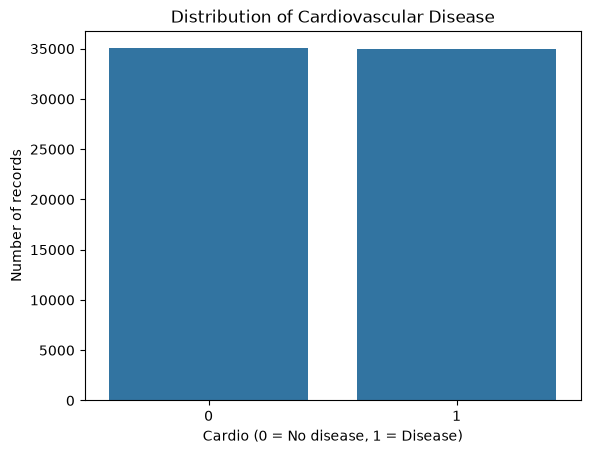

In [43]:
target_counts = raw["cardio"].value_counts()
print(target_counts, end="\n\n")
print((raw["cardio"].value_counts(normalize=True) * 100).round(2))

sns.countplot(data=raw, x="cardio")
plt.title("Distribution of Cardiovascular Disease")
plt.xlabel("Cardio (0 = No disease, 1 = Disease)")
plt.ylabel("Number of records")
plt.show()

In [44]:
age_in_years = (raw["age"] / 365.25).round(1)
print(age_in_years.describe())

count   70000.00
mean       53.30
std         6.76
min        29.60
25%        48.40
50%        53.90
75%        58.40
max        64.90
Name: age, dtype: float64


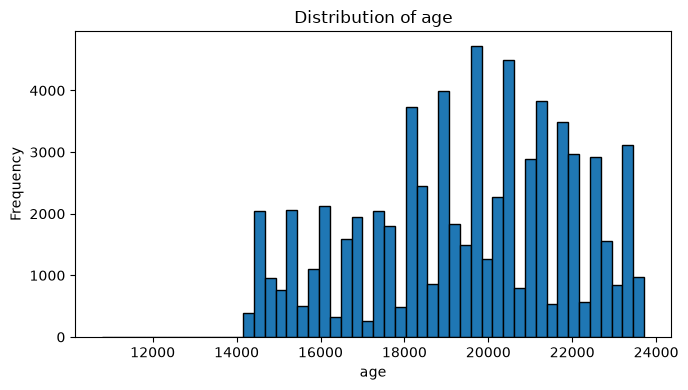

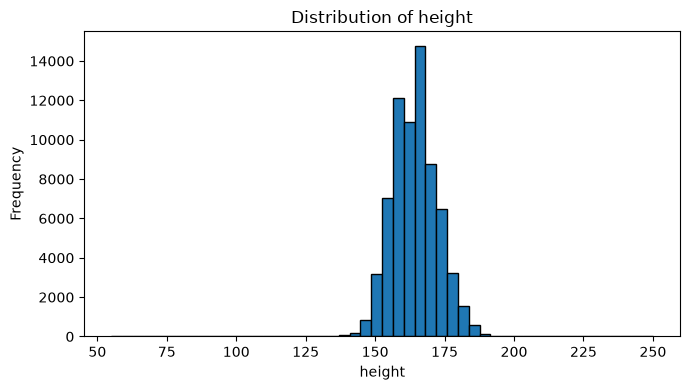

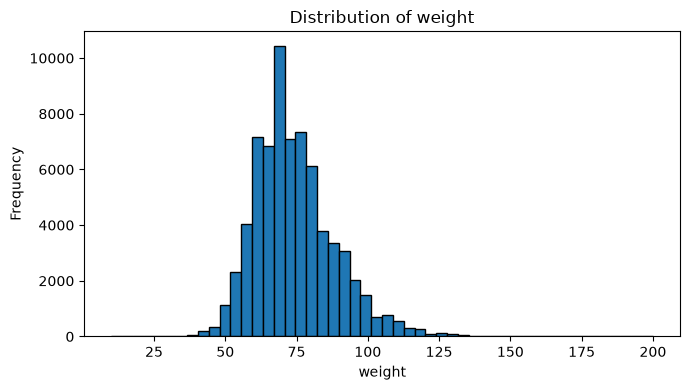

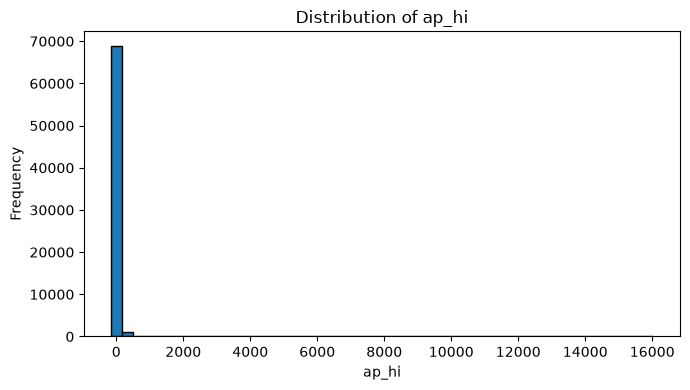

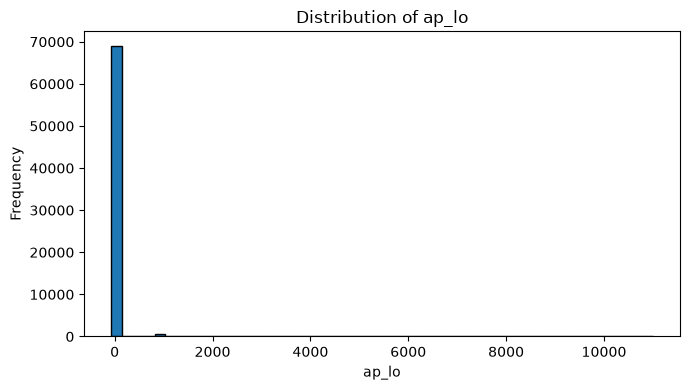

In [45]:
for col in NUM_COLS:
    fig, ax = plt.subplots(figsize=(7, 4))
    ax.hist(raw[col], bins=50, edgecolor="black")
    ax.set(title=f"Distribution of {col}", xlabel=col, ylabel="Frequency")
    fig.tight_layout()
    plt.show()

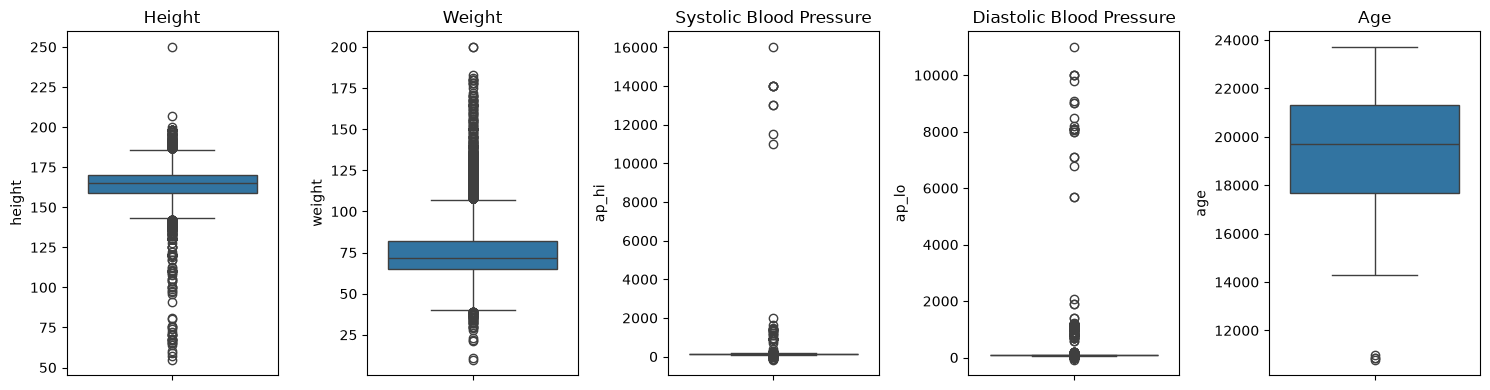

In [46]:
titles = {"height": "Height", "weight": "Weight",
          "ap_hi": "Systolic Blood Pressure",
          "ap_lo": "Diastolic Blood Pressure", "age": "Age"}

fig, axes = plt.subplots(1, len(titles), figsize=(15, 4))
for ax, (col, title) in zip(axes, titles.items()):
    sns.boxplot(y=raw[col], ax=ax)
    ax.set_title(title)
plt.tight_layout()
plt.show()

In [47]:
summary = raw[NUM_COLS].agg(["mean", "median", "skew"]).T
display(summary)

,mean,median,skew
age,19468.87,19703.00,-0.31
height,164.36,165.00,-0.64
weight,74.21,72.00,1.01
ap_hi,128.82,120.00,85.30
ap_lo,96.63,80.00,32.11


In [48]:
def iqr_profile(series):
    q1, q2, q3 = series.quantile([0.25, 0.50, 0.75])
    iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_out = int(((series < lo) | (series > hi)).sum())
    return {"Q1": q1, "Q2 (Median)": q2, "Q3": q3, "IQR": iqr,
            "lower_bound": lo, "upper_bound": hi,
            "potential_outliers": n_out,
            "outlier_percentage": n_out / len(series) * 100}

outlier_table = (pd.DataFrame({c: iqr_profile(raw[c]) for c in NUM_COLS})
                 .T.rename_axis("feature").reset_index())
display(outlier_table.round(2))

,feature,Q1,Q2 (Median),Q3,IQR,lower_bound,upper_bound,potential_outliers,outlier_percentage
0,age,17664.00,19703.00,21327.00,3663.00,12169.50,26821.50,4.00,0.01
1,height,159.00,165.00,170.00,11.00,142.50,186.50,519.00,0.74
2,weight,65.00,72.00,82.00,17.00,39.50,107.50,1819.00,2.60
3,ap_hi,120.00,120.00,140.00,20.00,90.00,170.00,1435.00,2.05
4,ap_lo,80.00,80.00,90.00,10.00,65.00,105.00,4632.00,6.62


In [49]:
for col in NUM_COLS:
    s = raw[col]
    q1, q3 = s.quantile([0.25, 0.75])
    fence = 1.5 * (q3 - q1)
    flagged = s[(s < q1 - fence) | (s > q3 + fence)].sort_values()

    print(f"\n=== {col} ===")
    print("Lowest potential outliers: ", flagged.head(10).to_list())
    print("Highest potential outliers:", flagged.tail(10).iloc[::-1].to_list())


=== age ===
Lowest potential outliers:  [10798, 10859, 10878, 10964]
Highest potential outliers: [10964, 10878, 10859, 10798]

=== height ===
Lowest potential outliers:  [55, 57, 59, 60, 64, 65, 65, 66, 67, 67]
Highest potential outliers: [250, 207, 200, 198, 198, 198, 198, 198, 198, 198]

=== weight ===
Lowest potential outliers:  [10.0, 11.0, 21.0, 22.0, 23.0, 28.0, 29.0, 30.0, 30.0, 30.0]
Highest potential outliers: [200.0, 200.0, 183.0, 181.0, 180.0, 180.0, 180.0, 180.0, 178.0, 178.0]

=== ap_hi ===
Lowest potential outliers:  [-150, -140, -120, -120, -115, -100, -100, 1, 1, 7]
Highest potential outliers: [16020, 14020, 14020, 14020, 14020, 13010, 13010, 11500, 11020, 2000]

=== ap_lo ===
Lowest potential outliers:  [-70, 0, 0, 0, 0, 0, 0, 0, 0, 0]
Highest potential outliers: [11000, 10000, 10000, 10000, 9800, 9100, 9011, 9011, 8500, 8200]


## 5. Cleaning

Decisions:
- Convert age from days to years and drop `id`.
- Implausible height/weight become `NaN` (rows are kept; they will be imputed with the median during modelling).
- Rows with impossible blood pressure are removed.

In [50]:
clean = raw.copy(deep=True)

clean["age_years"] = (clean["age"] / 365.25).round(1)
print(clean["age_years"].describe())

clean = clean.drop(columns="id")

count   70000.00
mean       53.30
std         6.76
min        29.60
25%        48.40
50%        53.90
75%        58.40
max        64.90
Name: age_years, dtype: float64


In [51]:
# Height / weight -> NaN (rows preserved)
clean.loc[~clean["height"].between(*HEIGHT_LIMITS), "height"] = np.nan
clean.loc[clean["weight"] < MIN_WEIGHT, "weight"] = np.nan

print("Missing heights:", clean["height"].isna().sum())
print("Missing weights:", clean["weight"].isna().sum())

Missing heights: 30
Missing weights: 7


In [52]:
def flag_bad_bp(frame):
    sys_bad = ~frame["ap_hi"].between(*SYS_LIMITS)
    dia_bad = ~frame["ap_lo"].between(*DIA_LIMITS)
    order_bad = frame["ap_hi"] <= frame["ap_lo"]
    return sys_bad | dia_bad | order_bad

bad_bp = flag_bad_bp(clean)

print("Rows to remove:", bad_bp.sum())
print("Rows remaining:", len(clean) - bad_bp.sum())

Rows to remove: 1334
Rows remaining: 68666


In [53]:
clean = clean[~bad_bp].copy()

print("Shape after cleaning:", clean.shape)
print("Remaining invalid BP rows:", flag_bad_bp(clean).sum())

Shape after cleaning: (68666, 13)
Remaining invalid BP rows: 0


## 6. Validation & export

In [54]:
display(clean.describe().T)
print("Rows removed overall:", len(raw) - len(clean))

clean.to_csv(CLEAN_FILE, index=False)
print("Saved to", CLEAN_FILE)

,count,mean,std,min,25%,50%,75%,max
age,68666.00,19464.57,2468.18,10798.00,17658.00,19701.00,21324.00,23713.00
gender,68666.00,1.35,0.48,1.00,1.00,1.00,2.00,2.00
height,68639.00,164.39,7.98,100.00,159.00,165.00,170.00,207.00
weight,68660.00,74.12,14.32,30.00,65.00,72.00,82.00,200.00
ap_hi,68666.00,126.67,16.68,70.00,120.00,120.00,140.00,240.00
ap_lo,68666.00,81.30,9.42,40.00,80.00,80.00,90.00,150.00
cholesterol,68666.00,1.36,0.68,1.00,1.00,1.00,2.00,3.00
gluc,68666.00,1.23,0.57,1.00,1.00,1.00,1.00,3.00
smoke,68666.00,0.09,0.28,0.00,0.00,0.00,0.00,1.00
alco,68666.00,0.05,0.22,0.00,0.00,0.00,0.00,1.00


Rows removed overall: 1334
Saved to cardio_cleaned.csv
